# 09 — Transfer Learning and Data Augmentation

### Getting more from few images: pretrained networks and synthetic variation

**Learning path:** `Deep Learning / Keras`  
**Notebook:** 09 of 12  
**Level:** Advanced  
**Primary tools:** Python, NumPy, Matplotlib, Pillow, Keras 3 (`keras.applications`)  
**Dataset:** *Oxford 102 Flowers* (as in Notebook 08), with the same stratified split

---

## Learning objectives

By the end of this notebook, you should be able to:

1. Explain **image rescaling** (nearest-neighbour, bilinear, Lanczos), implement bilinear interpolation from scratch, and explain **aliasing** when an image is shrunk.
2. Formulate **data augmentation** as minimizing a *vicinal risk*, write geometric augmentations as **affine maps** (rotation, scaling, translation, flip in homogeneous coordinates), and implement an affine warp with bilinear sampling in NumPy.
3. Prove that **input-noise augmentation equals an L2 penalty** for a linear model, and verify it by simulation.
4. Use Keras augmentation layers inside a model (random in training, identity at inference) and measure their effect on a network trained from scratch.
5. Define **transfer learning**, distinguish **feature extraction** (frozen backbone) from **fine-tuning**, and explain why only a few top layers should be unfrozen with a small learning rate, and why **BatchNorm layers stay frozen**.
6. Load a pretrained **MobileNetV2**, extract features, and train **linear probes** (closed-form ridge classifier and a Keras softmax head).
7. Fine-tune the network, measure **how far each layer moved** from its pretrained weights, and compare all approaches fairly on the same split with intervals and a paired test.
8. Draw and interpret **data-efficiency curves** (accuracy against the number of training images per class).
9. State the **caveats of transfer learning**: domain overlap and contamination between the pretraining data and the test data, confounded comparisons, and licensing.

> **What is new compared with Notebook 08?** There, a small CNN trained from scratch on about 48 images per class overfitted and was limited by the low resolution. Here we attack both limitations: *augmentation* creates plausible new training images, and *transfer learning* starts from a network that has already learned general visual features from over a million images. The evaluation habits of Notebook 07 (honest split, intervals, paired comparisons) are applied throughout.

## 1. Two remedies for scarce data

A network with $P$ parameters trained on $N$ images can memorize the training set when $P \gg N$. Besides regularization (Notebook 06), there are two ways to change the problem itself.

| | Idea | What it changes |
|---|---|---|
| **Data augmentation** | apply random, label-preserving transformations (flip, rotate, zoom, shift, change brightness and contrast) to each training image every epoch | the **training distribution**: the network never sees exactly the same image twice, and learns the invariances we build in |
| **Transfer learning** | start from a network trained on a large source task (here: ImageNet, 1.2 million images, 1,000 classes) and adapt it to the target task | the **hypothesis class and its starting point**: low-level features (edges, textures, colours, simple shapes) are largely universal and need not be relearned from 4,900 images |

The plan of this notebook:

1. **Part I** — the mathematics: image rescaling, augmentation as affine maps and as a regularizer, and the formal picture of transfer learning.
2. **Part II** — experiments: (E1) augmentation for a CNN from scratch; (E2) frozen pretrained features with linear probes; (E3) fine-tuning; a final comparison on the test set; (E4) data-efficiency curves.

### 1.1 A necessary note on fairness

The pretrained network expects larger images than the 64 × 64 images of Notebook 08, so the transfer models use **128 × 128** inputs. Comparing "from scratch at 64 pixels" with "pretrained at 128 pixels" confounds the *method* with the *resolution*; we will state this in the interpretation and propose a control in the exercises.

## 2. Set up the environment

We use Keras 3 with the TensorFlow backend. The first call to `keras.applications.MobileNetV2(weights="imagenet")` **downloads the pretrained weights** (about 10–15 MB), so an internet connection is needed once.

You also need the Flowers files from Notebook 08 in `data/flowers102/` (`jpg/`, `imagelabels.mat`, `setid.mat`).

**Runtime.** On a CPU: extracting features for all 8,189 images takes a few minutes; training from scratch with augmentation (three models) takes roughly 15–30 minutes; fine-tuning takes another 10–20 minutes. Set `QUICK_MODE = True` for a much shorter first run (fewer epochs, fewer sizes).

In [ ]:
# If needed, install the packages in the active Jupyter environment:
# %pip install -U keras tensorflow numpy pandas matplotlib pillow scipy

In [1]:
# Select the backend BEFORE importing Keras.
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import sys, json, math, time
from math import comb

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image, ImageOps
from scipy.io import loadmat

import keras

SEED = 42
keras.utils.set_random_seed(SEED)

QUICK_MODE = False                       # True: fewer epochs and sizes (for a first quick read)
EPOCH_SCALE = 0.4 if QUICK_MODE else 1.0
def epochs_for(n):
    return max(4, int(round(n * EPOCH_SCALE)))

SIZE_SCRATCH = 64                         # input size of the networks trained from scratch (as in Notebook 08)
SIZE_PRETRAINED = 128                     # input size of the pretrained network (MobileNetV2 supports 96, 128, 160, 192, 224)

ARTIFACT_DIR = "artifacts_09"
FIG_DIR = "figures_09"
for folder in (ARTIFACT_DIR, FIG_DIR):
    os.makedirs(folder, exist_ok=True)

print("Python :", sys.version.split()[0])
print("Keras  :", keras.__version__, "| backend:", keras.backend.backend())
print("NumPy  :", np.__version__, "| pandas:", pd.__version__, "| Pillow:", Image.__version__)
print("Input sizes: scratch", SIZE_SCRATCH, "| pretrained", SIZE_PRETRAINED, "| quick mode:", QUICK_MODE)

Python : 3.11.0
Keras  : 3.15.1 | backend: tensorflow
NumPy  : 2.4.6 | pandas: 2.3.3 | Pillow: 12.3.0
Input sizes: scratch 64 | pretrained 128 | quick mode: False


## 3. Visual style

In [2]:
COLORS = {"blue": "#2563EB", "orange": "#F59E0B", "green": "#10B981", "red": "#EF4444",
          "purple": "#8B5CF6", "gray": "#6B7280", "dark": "#111827", "light": "#E5E7EB",
          "teal": "#0D9488", "pink": "#DB2777"}
METHOD_COLORS = {"CNN from scratch": COLORS["gray"], "Ridge probe (frozen features)": COLORS["teal"],
                 "Softmax probe (frozen features)": COLORS["blue"], "Fine-tuned MobileNetV2": COLORS["orange"]}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": COLORS["gray"], "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLORS["light"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 10,
    "axes.labelcolor": COLORS["dark"], "xtick.color": COLORS["dark"], "ytick.color": COLORS["dark"],
    "font.size": 10, "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2.0,
})

SAVE_FIGURES = True
def finish(fig, name, pad=1.0):
    fig.tight_layout(pad=pad)
    if SAVE_FIGURES:
        fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 4. Data: the same images and the same split as Notebook 08

We load the images at two sizes (64 × 64 for the networks from scratch, 128 × 128 for the pretrained network) with the same loader as in Notebook 08 (resize the shorter side, crop the centre; the result is cached in `.npz` files). The stratified 60/20/20 split uses the **same function and the same seed**, so the three partitions contain exactly the same images at both resolutions, and all methods are evaluated on the same test images — which is required for the **paired** comparisons later.

In [3]:
FLOWERS_DIR = os.path.join("data", "flowers102")
RESAMPLE = getattr(Image, "Resampling", Image).LANCZOS
N_CLASSES = 102

def image_path(i):
    return os.path.join(FLOWERS_DIR, "jpg", f"image_{i + 1:05d}.jpg")

def load_image_file(i, size):
    with Image.open(image_path(i)) as im:
        return np.asarray(ImageOps.fit(im.convert("RGB"), (size, size), method=RESAMPLE))

def load_flowers(size):
    cache = os.path.join(FLOWERS_DIR, f"flowers102_{size}px.npz")
    if os.path.exists(cache):
        with np.load(cache) as f:
            return f["images"], f["labels"]
    labels_file = os.path.join(FLOWERS_DIR, "imagelabels.mat")
    if not (os.path.exists(labels_file) and os.path.isdir(os.path.join(FLOWERS_DIR, "jpg"))):
        raise RuntimeError(f"Flowers files not found in '{FLOWERS_DIR}'. See Notebook 08 for the download instructions "
                           "(jpg/ folder from 102flowers.tgz, imagelabels.mat, setid.mat).")
    labels = loadmat(labels_file, squeeze_me=True)["labels"].astype(np.int64) - 1
    images = np.empty((len(labels), size, size, 3), dtype=np.uint8)
    t0 = time.time()
    for i in range(len(labels)):
        images[i] = load_image_file(i, size)
        if (i + 1) % 2000 == 0:
            print(f"  size {size}: {i + 1} / {len(labels)} images ({time.time() - t0:.0f} s)")
    np.savez_compressed(cache, images=images, labels=labels)
    return images, labels

images_64, labels_all = load_flowers(SIZE_SCRATCH)
images_128, labels_128 = load_flowers(SIZE_PRETRAINED)
assert np.array_equal(labels_all, labels_128) and len(labels_all) == 8189
print("Images:", images_64.shape, "and", images_128.shape)

  size 128: 2000 / 8189 images (11 s)
  size 128: 4000 / 8189 images (21 s)
  size 128: 6000 / 8189 images (32 s)
  size 128: 8000 / 8189 images (42 s)
Images: (8189, 64, 64, 3) and (8189, 128, 128, 3)


In [4]:
def stratified_split_indices(labels, val_fraction=0.2, test_fraction=0.2, seed=SEED):
    """Same function and seed as Notebook 08: train/validation/test indices, every class in every partition."""
    split_rng = np.random.default_rng(seed)
    tr, va, te = [], [], []
    for c in np.unique(labels):
        idx = split_rng.permutation(np.flatnonzero(labels == c))
        n_val = max(1, int(round(val_fraction * len(idx)))); n_test = max(1, int(round(test_fraction * len(idx))))
        va.append(idx[:n_val]); te.append(idx[n_val:n_val + n_test]); tr.append(idx[n_val + n_test:])
    return [split_rng.permutation(np.concatenate(p)) for p in (tr, va, te)]

tr_idx, va_idx, te_idx = stratified_split_indices(labels_all)
assert len(set(tr_idx) | set(va_idx) | set(te_idx)) == len(labels_all)

y_train, y_val, y_test = (labels_all[i].astype("int32") for i in (tr_idx, va_idx, te_idx))
X64 = {"train": images_64[tr_idx], "val": images_64[va_idx], "test": images_64[te_idx]}
X128 = {"train": images_128[tr_idx], "val": images_128[va_idx], "test": images_128[te_idx]}
y = {"train": y_train, "val": y_val, "test": y_test}

print("Training / validation / test images:", len(y_train), "/", len(y_val), "/", len(y_test))
print("Training images per class: min", np.bincount(y_train).min(), "| median", int(np.median(np.bincount(y_train))), "| max", np.bincount(y_train).max())
print("Chance accuracy: top-1 =", round(1 / N_CLASSES, 4), "| top-5 =", round(5 / N_CLASSES, 4))

Training / validation / test images: 4923 / 1633 / 1633
Training images per class: min 24 | median 40 | max 154
Chance accuracy: top-1 = 0.0098 | top-5 = 0.049


# Part I — The mathematics

## 5. Image rescaling

Pretrained networks expect a particular input size, and our images come in many sizes, so **resizing** is part of every vision pipeline. Resizing means *resampling* the image on a new pixel grid, which requires **interpolation**.

Use the coordinate convention in which pixel $i$ covers the interval $[i, i+1)$ and has its centre at $i + \tfrac{1}{2}$. To compute output pixel $u$ of an image of $n_{out}$ pixels from an input of $n_{in}$ pixels, find its centre in the input:

$$
x = (u + \tfrac{1}{2})\,\frac{n_{in}}{n_{out}} - \tfrac{1}{2} .
$$

| Method | Output value |
|---|---|
| **Nearest neighbour** | the input pixel closest to $x$ (blocky, no new values) |
| **Bilinear** | $f(x) = (1-w)\,f_{\lfloor x \rfloor} + w\,f_{\lfloor x \rfloor + 1}$ with $w = x - \lfloor x \rfloor$; in 2D, apply it along rows and then columns (equivalently, a weighted average of the 4 nearest pixels with weights proportional to the opposite areas) |
| **Lanczos / bicubic** | weighted average over a larger neighbourhood with a windowed-sinc kernel (sharper) |

### 5.1 Aliasing

Bilinear interpolation uses only the 2 (per axis) nearest pixels, however much the image is shrunk. When shrinking by a factor $r > 1$, a proper resampler must first **average over about $r$ input pixels** (a low-pass filter), otherwise fine patterns whose frequency exceeds the Nyquist frequency of the *new* grid (half a cycle per new pixel) are misrepresented as coarse patterns — **aliasing** (moiré). Image libraries such as Pillow apply this *antialiasing* automatically when shrinking; naive nearest or bilinear lookups do not.

We implement nearest and bilinear resampling from scratch, check the bilinear version against Pillow for **enlarging** (where there is no antialiasing issue), and then show aliasing on a test pattern.

In [5]:
def resize_nearest(img, out_h, out_w):
    in_h, in_w = img.shape[:2]
    ys = np.minimum(((np.arange(out_h) + 0.5) * in_h / out_h).astype(int), in_h - 1)
    xs = np.minimum(((np.arange(out_w) + 0.5) * in_w / out_w).astype(int), in_w - 1)
    return img[ys][:, xs]

def resize_bilinear(img, out_h, out_w):
    """Bilinear interpolation with half-pixel centres and clamped borders (no antialiasing)."""
    img = img.astype(float)
    if img.ndim == 2:
        img = img[:, :, None]
    in_h, in_w = img.shape[:2]
    ys = np.clip((np.arange(out_h) + 0.5) * in_h / out_h - 0.5, 0, in_h - 1)
    xs = np.clip((np.arange(out_w) + 0.5) * in_w / out_w - 0.5, 0, in_w - 1)
    y0, x0 = np.floor(ys).astype(int), np.floor(xs).astype(int)
    y1, x1 = np.minimum(y0 + 1, in_h - 1), np.minimum(x0 + 1, in_w - 1)
    wy, wx = (ys - y0)[:, None, None], (xs - x0)[None, :, None]
    top = img[y0][:, x0] * (1 - wx) + img[y0][:, x1] * wx
    bottom = img[y1][:, x0] * (1 - wx) + img[y1][:, x1] * wx
    return top * (1 - wy) + bottom * wy

# Check: enlarging 32 x 32 -> 64 x 64 with our bilinear function against Pillow's bilinear resize.
small = images_64[0][::2, ::2]
ours = resize_bilinear(small, 64, 64)
pillow = np.asarray(Image.fromarray(small).resize((64, 64), Image.BILINEAR)).astype(float)
print("Enlarging: maximum difference to Pillow (in 0-255 intensity levels):", round(float(np.abs(ours - pillow).max()), 3))
assert np.abs(ours - pillow).max() <= 1.0                                             # rounding to uint8 only

Enlarging: maximum difference to Pillow (in 0-255 intensity levels): 1.0


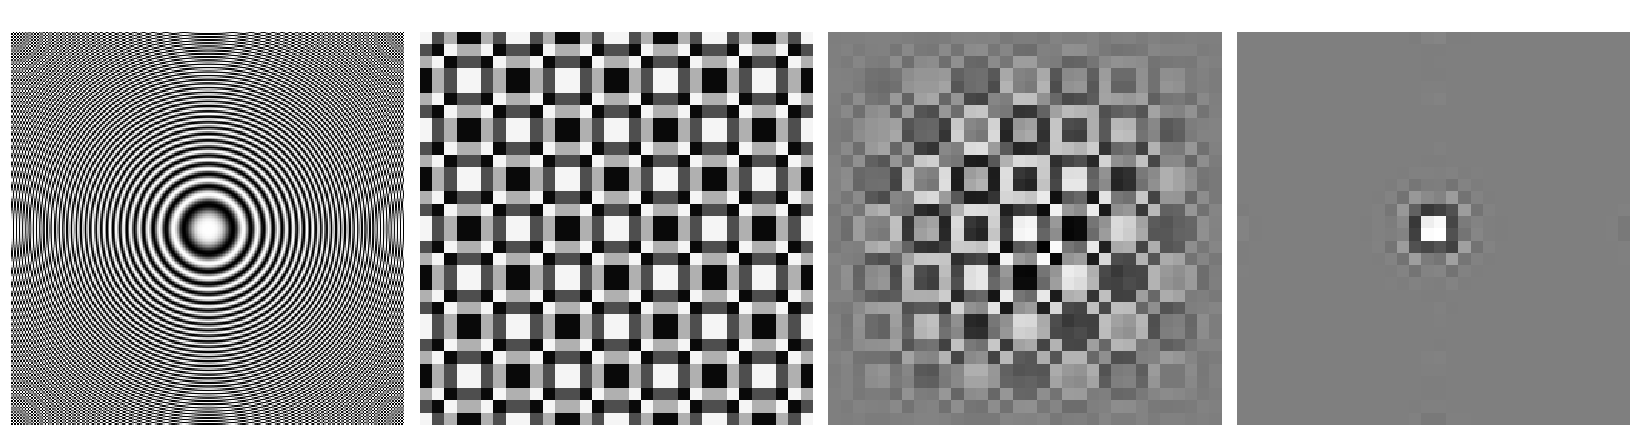

Mean squared error against the area-averaged reference, nearest                     :   8035.2
Mean squared error against the area-averaged reference, bilinear (no antialiasing)  :   1909.4
Mean squared error against the area-averaged reference, Lanczos (antialiased)       :     39.9


In [6]:
# Aliasing: a "zone plate" has spatial frequencies that sweep from low (centre) to high (corners).
N0, factor = 256, 8
yy, xx = np.mgrid[0:N0, 0:N0] - N0 / 2
zone = 0.5 + 0.5 * np.cos(np.pi * (xx**2 + yy**2) / N0)                               # values in [0, 1]
zone_u8 = (255 * zone).astype(np.uint8)
target = N0 // factor

nearest = resize_nearest(zone_u8, target, target).astype(float)
bilinear = resize_bilinear(zone_u8, target, target)[:, :, 0]
lanczos = np.asarray(Image.fromarray(zone_u8).resize((target, target), Image.LANCZOS)).astype(float)
reference = (255 * zone).reshape(target, factor, target, factor).mean(axis=(1, 3))     # area average (the physically sensible answer)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.9))
for ax, (img, title) in zip(axes, [(zone_u8, f"Original ({N0}\u00d7{N0})"), (nearest, f"Nearest ({target}\u00d7{target})"),
                                  (bilinear, "Bilinear, no antialiasing"), (lanczos, "Lanczos with antialiasing (Pillow)")]):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255, interpolation="nearest"); ax.set_title(title, fontsize=10); ax.axis("off")
finish(fig, "01_aliasing")
for name, img in [("nearest", nearest), ("bilinear (no antialiasing)", bilinear), ("Lanczos (antialiased)", lanczos)]:
    print(f"Mean squared error against the area-averaged reference, {name:28s}: {np.mean((img - reference) ** 2):8.1f}")

The shrunk nearest-neighbour and bilinear images contain **spurious ring patterns** that are not in the original (aliasing), while the antialiased version is close to the area average. For photographs the effect is subtler, but the lesson is practical: **resize with a library that antialiases** (Pillow with `LANCZOS`, as in our loader, or `keras.layers.Resizing(..., antialias=True)`), and apply *exactly the same* resizing to training and prediction images.

## 6. Data augmentation

### 6.1 Augmentation as vicinal risk minimization

Standard training minimizes the empirical risk over the $N$ training pairs. With a family $\mathcal{T}$ of transformations (flips, rotations, ...) and a distribution over them, **augmented training** minimizes

$$
\hat{R}_{\text{aug}}(\theta) = \frac{1}{N}\sum_{i=1}^{N}\mathbb{E}_{t \sim \mathcal{T}}\Big[\ell\big(f_\theta(t(x_i)),\, y_i\big)\Big],
$$

which replaces each training point by a *neighbourhood* (the "vicinity") of transformed versions — **vicinal risk minimization** (Chapelle *et al.*, 2000). In practice the expectation is estimated by drawing a *new random transformation every time an image is used*, so each epoch sees different images.

Two points are essential:

1. **Label preservation.** Augmentation encodes prior knowledge: "a flower rotated by 20° is still the same species". This must be true. Flipping a flower horizontally is harmless; flipping a letter or a molecule with chirality may change its meaning, and a vertical flip is not label-preserving for objects with a fixed orientation (such as many animals or landscapes). For microscopy, rotations and flips are usually valid; colour changes may *not* be if colour carries the biology (a stain intensity).
2. **The effective number of samples does not grow like $N \times |\mathcal{T}|$.** Transformed copies are strongly correlated with the original. Augmentation is a *regularizer* that builds in invariances; it cannot replace the information that new independent samples would bring.

### 6.2 Geometric transformations as affine maps

In homogeneous coordinates a pixel position $(x, y)$ is the vector $p = (x, y, 1)^{\top}$, and common transformations are $3 \times 3$ matrices:

$$
T(t_x, t_y) = \begin{pmatrix} 1 & 0 & t_x \\ 0 & 1 & t_y \\ 0 & 0 & 1 \end{pmatrix}, \quad
R(\theta) = \begin{pmatrix} \cos\theta & -\sin\theta & 0 \\ \sin\theta & \cos\theta & 0 \\ 0 & 0 & 1 \end{pmatrix}, \quad
S(s_x, s_y) = \begin{pmatrix} s_x & 0 & 0 \\ 0 & s_y & 0 \\ 0 & 0 & 1 \end{pmatrix}, \quad
F_h = \begin{pmatrix} -1 & 0 & W-1 \\ 0 & 1 & 0 \\ 0 & 0 & 1 \end{pmatrix}.
$$

To rotate or scale **about the image centre** $c$, translate the centre to the origin, transform, and translate back: $A = T(c)\,M\,T(-c)$. Matrices are applied right-to-left, and **order matters** (rotating then translating differs from translating then rotating, because matrix products do not commute).

**Inverse mapping.** To produce the output image, we do not push input pixels forward (which leaves holes); for every *output* pixel $p'$ we compute where it comes from, $p = A^{-1}p'$, and **sample the input there with bilinear interpolation** (Section 5). Positions that fall outside the image are clamped to the border here (Keras layers offer `reflect`, `constant`, `nearest`, or `wrap` fill modes).

### 6.3 Photometric transformations

$$
\text{brightness: } x' = \operatorname{clip}(x + b), \qquad
\text{contrast: } x' = \operatorname{clip}\big((x - \mu)\,c + \mu\big),
$$

where $\mu$ is the mean intensity of the image (per channel) and $c > 0$ the contrast factor ($c = 1$ leaves the image unchanged).

We implement the affine warp and verify it on cases where the exact answer is known: a horizontal flip must equal `img[:, ::-1]`, and a rotation by 90° must equal `np.rot90`.

In [7]:
def translation(tx, ty):  return np.array([[1, 0, tx], [0, 1, ty], [0, 0, 1.0]])
def rotation(theta):      return np.array([[np.cos(theta), -np.sin(theta), 0], [np.sin(theta), np.cos(theta), 0], [0, 0, 1.0]])
def scaling(sx, sy):      return np.array([[sx, 0, 0], [0, sy, 0], [0, 0, 1.0]])
def flip_horizontal(W):   return np.array([[-1, 0, W - 1], [0, 1, 0], [0, 0, 1.0]])
def about_center(M, H, W):
    c = translation((W - 1) / 2, (H - 1) / 2)
    return c @ M @ np.linalg.inv(c)

def affine_warp(img, A):
    """Warp an image with the 3x3 affine map A (input -> output coordinates), by inverse mapping with bilinear
    sampling; positions outside the image are clamped to the border."""
    img = img.astype(float)
    H, W = img.shape[:2]
    yy, xx = np.mgrid[0:H, 0:W]
    src = np.linalg.inv(A) @ np.stack([xx.ravel(), yy.ravel(), np.ones(H * W)])
    sx, sy = np.clip(src[0].reshape(H, W), 0, W - 1), np.clip(src[1].reshape(H, W), 0, H - 1)
    x0, y0 = np.floor(sx).astype(int), np.floor(sy).astype(int)
    x1, y1 = np.minimum(x0 + 1, W - 1), np.minimum(y0 + 1, H - 1)
    wx, wy = (sx - x0)[..., None], (sy - y0)[..., None]
    top = img[y0, x0] * (1 - wx) + img[y0, x1] * wx
    bottom = img[y1, x0] * (1 - wx) + img[y1, x1] * wx
    return top * (1 - wy) + bottom * wy

test_img = images_64[5].astype(float)
H_, W_ = test_img.shape[:2]

flipped = affine_warp(test_img, flip_horizontal(W_))
print("Horizontal flip equals img[:, ::-1]:", np.allclose(flipped, test_img[:, ::-1], atol=1e-9))
assert np.allclose(flipped, test_img[:, ::-1], atol=1e-9)

rotated = affine_warp(test_img, about_center(rotation(np.pi / 2), H_, W_))
matches = [k for k in (1, 3) if np.allclose(rotated, np.rot90(test_img, k), atol=1e-6)]
print("Rotation by 90 degrees about the centre equals np.rot90 with k =", matches)
assert matches

# Order matters: rotating then translating is not the same as translating then rotating.
R_, T_ = about_center(rotation(0.5), H_, W_), translation(10, 0)
print("Largest entry of (R T - T R):", round(float(np.abs(R_ @ T_ - T_ @ R_).max()), 3), "(nonzero: the order of the operations matters)")

# Photometric transformations.
brightness = lambda img, b: np.clip(img + b, 0, 255)
contrast = lambda img, c: np.clip((img - img.mean(axis=(0, 1))) * c + img.mean(axis=(0, 1)), 0, 255)
print("Contrast factor 1 leaves the image unchanged:", np.allclose(contrast(test_img, 1.0), test_img))

Horizontal flip equals img[:, ::-1]: True
Rotation by 90 degrees about the centre equals np.rot90 with k = [3]
Largest entry of (R T - T R): 4.794 (nonzero: the order of the operations matters)
Contrast factor 1 leaves the image unchanged: True


### 6.4 Why augmentation regularizes: input noise is an L2 penalty

Consider the simplest augmentation, **additive Gaussian noise** $x \mapsto x + \varepsilon$ with $\varepsilon \sim \mathcal{N}(0, \sigma^2 I)$, for a linear model $f(x) = w^{\top}x$ with squared loss. Because $\mathbb{E}[\varepsilon] = 0$ and $\mathbb{E}[\varepsilon\varepsilon^{\top}] = \sigma^2 I$,

$$
\mathbb{E}_{\varepsilon}\big[(y - w^{\top}(x + \varepsilon))^2\big]
= (y - w^{\top}x)^2 + \sigma^2\,\lVert w \rVert^2 .
$$

(*Proof:* $y - w^{\top}(x+\varepsilon) = (y - w^{\top}x) - w^{\top}\varepsilon$; expand the square; the cross term has zero mean and $\mathbb{E}[(w^{\top}\varepsilon)^2] = \sigma^2\lVert w\rVert^2$.)

**Training with noise-augmented inputs is therefore exactly ridge regression** with penalty $\lambda = \sigma^2$ (per sample): this is the result of Bishop (1995), and the same mechanism as the Dropout result of Notebook 06. For a smooth nonlinear model, a second-order Taylor expansion gives, for small $\sigma$, a penalty on the **sensitivity of the model to its input**, $\approx \sigma^2\lVert\nabla_x f(x)\rVert^2$ (plus a term involving the curvature). Geometric augmentations act in the same spirit: they penalize outputs that change when the image undergoes transformations that should not change the label.

In [8]:
rg = np.random.default_rng(0)
d = 12
w_vec, x_vec, y_val_scalar, sigma = rg.normal(size=d), rg.normal(size=d), 0.7, 0.4

noise = rg.normal(0, sigma, size=(500_000, d))
monte_carlo = np.mean((y_val_scalar - (x_vec + noise) @ w_vec) ** 2)
formula = (y_val_scalar - w_vec @ x_vec) ** 2 + sigma**2 * np.sum(w_vec**2)
print(f"Monte-Carlo average loss with noisy inputs: {monte_carlo:.4f}")
print(f"Loss without noise + sigma^2 * ||w||^2     : {formula:.4f}")
print(f"Relative difference: {abs(monte_carlo / formula - 1):.4f}")
assert abs(monte_carlo / formula - 1) < 0.01

Monte-Carlo average loss with noisy inputs: 2.7682
Loss without noise + sigma^2 * ||w||^2     : 2.7659
Relative difference: 0.0008


### 6.5 Augmentation layers in Keras

Keras provides augmentation as **layers** (`RandomFlip`, `RandomRotation`, `RandomZoom`, `RandomTranslation`, `RandomContrast`, ...). Put inside a model, they are **active only during training** and act as the identity at inference. Note the units: `RandomRotation(0.05)` rotates by a random angle in $\pm 0.05 \times 360^{\circ} = \pm 18^{\circ}$; `RandomZoom(0.15)` zooms by up to 15% in or out; `RandomTranslation(0.1, 0.1)` shifts by up to 10% of the height and width.

We define three augmentation settings for the experiments, and check the train/inference behaviour.

In [9]:
def make_augmentation(kind):
    """Augmentation pipelines compared in Experiment E1 (the layers are random only in training mode)."""
    if kind == "none":
        return None
    if kind == "flip":
        return keras.Sequential([keras.layers.RandomFlip("horizontal")], name="augment_flip")
    if kind == "flip+geometric+contrast":
        return keras.Sequential([keras.layers.RandomFlip("horizontal"), keras.layers.RandomRotation(0.05),
                                 keras.layers.RandomZoom(0.15), keras.layers.RandomTranslation(0.1, 0.1),
                                 keras.layers.RandomContrast(0.2)], name="augment_full")
    raise ValueError(kind)

aug_layers = make_augmentation("flip+geometric+contrast")
batch = np.repeat(X64["train"][:1].astype("float32"), 8, axis=0)                    # 8 copies of the same image
out_inference = keras.ops.convert_to_numpy(aug_layers(batch, training=False))
out_training = keras.ops.convert_to_numpy(aug_layers(batch, training=True))

print("Inference mode: output equals the input:", np.allclose(out_inference, batch))
print("Training mode : the 8 copies are different from each other (mean pixel std across copies):", round(float(out_training.std(axis=0).mean()), 2))
assert np.allclose(out_inference, batch) and out_training.std(axis=0).mean() > 0.5

Inference mode: output equals the input: True
Training mode : the 8 copies are different from each other (mean pixel std across copies): 35.68


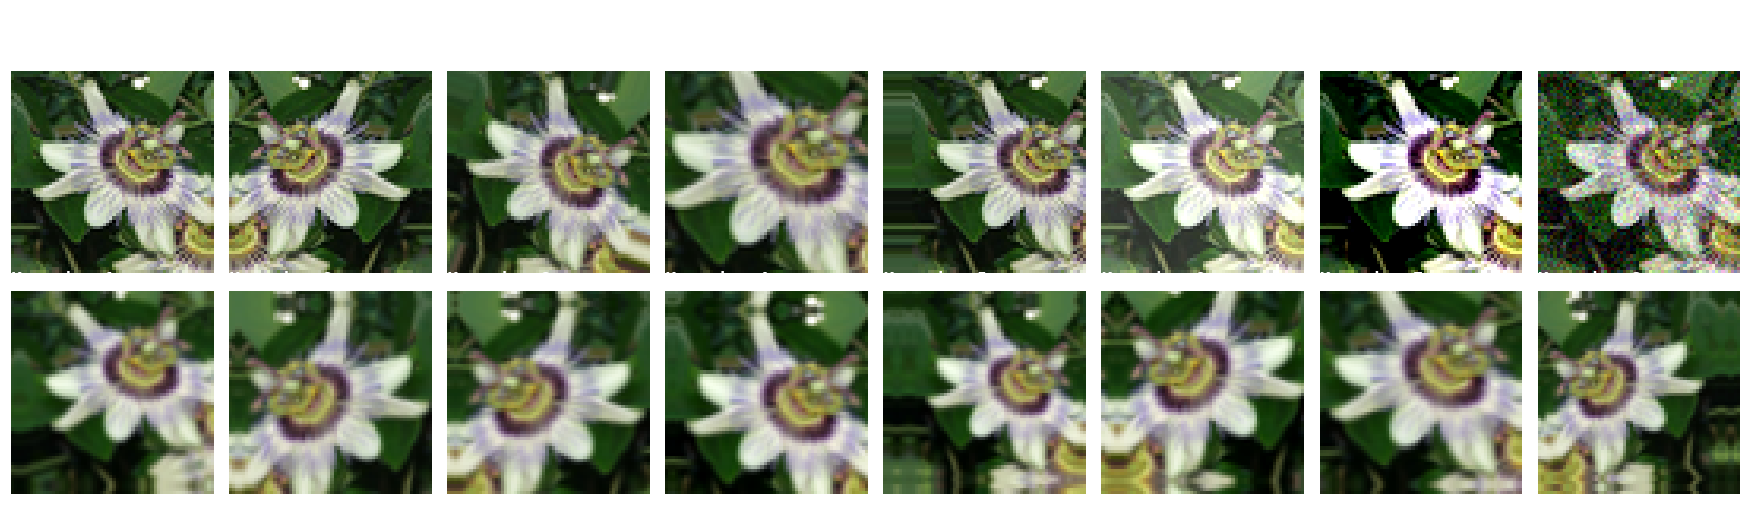

In [10]:
base_img = images_64[5]
H_, W_ = base_img.shape[:2]
numpy_versions = [
    ("Original", base_img.astype(float)),
    ("Horizontal flip", affine_warp(base_img, flip_horizontal(W_))),
    ("Rotation +20\u00b0", affine_warp(base_img, about_center(rotation(np.deg2rad(20)), H_, W_))),
    ("Zoom in 1.3\u00d7", affine_warp(base_img, about_center(scaling(1.3, 1.3), H_, W_))),
    ("Shift 8 px right", affine_warp(base_img, translation(8, 0))),
    ("Brightness +40", brightness(base_img.astype(float), 40)),
    ("Contrast \u00d71.6", contrast(base_img.astype(float), 1.6)),
    ("Gaussian noise", np.clip(base_img + np.random.default_rng(1).normal(0, 20, base_img.shape), 0, 255)),
]
keras_draws = keras.ops.convert_to_numpy(aug_layers(np.repeat(base_img[None].astype("float32"), 8, axis=0), training=True))

fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for ax, (title, img) in zip(axes[0], numpy_versions):
    ax.imshow(np.clip(img, 0, 255).astype(np.uint8)); ax.set_title(title, fontsize=9); ax.axis("off")
for k, ax in enumerate(axes[1]):
    ax.imshow(np.clip(keras_draws[k], 0, 255).astype(np.uint8)); ax.axis("off"); ax.set_title(f"Keras draw {k + 1}", fontsize=9)
fig.suptitle("Top: our NumPy transformations (one at a time).  Bottom: eight random draws of the combined Keras pipeline", fontsize=12, fontweight="bold", x=0.01, ha="left", y=1.0)
finish(fig, "02_augmentation_gallery")

## 7. Transfer learning

### 7.1 The idea

Let a network be a composition $f = g_{\psi} \circ \varphi_{\theta}$: a **feature extractor** $\varphi_\theta$ (the convolutional backbone) that maps an image to a feature vector $z = \varphi_\theta(x) \in \mathbb{R}^{d}$, and a **head** $g_\psi$ (here a linear layer with softmax) that maps $z$ to class probabilities. **Pretraining** on a large source task (ImageNet classification) gives parameters $\theta_0$ for which $\varphi_{\theta_0}$ already produces features useful for many other visual tasks:

- early layers learn **generic** features (edges, colour blobs, textures) that are similar in almost any natural-image task;
- later layers learn more **task-specific** combinations.

### 7.2 Two ways to use the pretrained backbone

| Strategy | What is trained | Parameters trained | Use when |
|---|---|---|---|
| **Feature extraction** (frozen backbone, "linear probe") | only the head $\psi$ | $d\cdot K + K$ (here $1280 \times 102 + 102 = 130{,}662$) | very little data, or as the first step |
| **Fine-tuning** | the head **and** the top part of the backbone | many more | enough data, and the target domain differs from the source |

Feature extraction has a big practical advantage: the frozen backbone is a fixed function, so the features of every image can be **computed once** and the head trained in seconds (a closed-form ridge classifier is even possible, Notebook 07).

### 7.3 Measuring feature quality: a separation ratio

A good feature space makes classes compact and well separated. With class means $\mu_c$, overall mean $\mu$, and $N_c$ samples in class $c$, define the between-class and within-class scatter

$$
S_B = \frac{1}{N}\sum_{c} N_c (\mu_c - \mu)(\mu_c - \mu)^{\top}, \qquad
S_W = \frac{1}{N}\sum_{c}\sum_{i \in c}(x_i - \mu_c)(x_i - \mu_c)^{\top}, \qquad
J = \frac{\operatorname{tr} S_B}{\operatorname{tr} S_W} .
$$

A larger $J$ means more separable classes (on average, in the full space). Comparing $J$ for raw pixels and for pretrained features gives a quantitative first look at *why* transfer works; we do it in Section 10.

### 7.4 Fine-tuning: three rules and their reasons

1. **Train the head first** (or start from a head already trained on frozen features). A randomly initialized head produces large, meaningless gradients that would flow into the backbone and destroy the pretrained features in the first few steps.
2. **Use a small learning rate for the backbone** (here $10^{-4}$, ten times smaller than the usual $10^{-3}$) and unfreeze only the top layers. The pretrained solution is a good starting point *because* it is close to what we need; large steps move the weights far away from it and discard what was learned. A formal version of this idea is to add the penalty $\tfrac{\lambda}{2}\lVert\theta - \theta_0\rVert^2$ to the loss (the *L2-SP* regularizer; the penalty pulls towards the pretrained weights rather than towards zero).
3. **Keep the BatchNorm layers frozen** (in *inference* mode). In training mode a BatchNorm layer normalizes with the statistics of the current mini-batch and updates its running mean and variance. With few images, small batches, and a new image distribution, those statistics would shift away from the values that the following pretrained layers expect. In inference mode the layer is a fixed affine transformation $y = \gamma\,(x - \mu)/\sqrt{\sigma^2 + \varepsilon} + \beta$ with the stored $\mu, \sigma^2$, so the pretrained features stay consistent. (In Keras, setting `layer.trainable = False` on a BatchNormalization layer also puts it in inference mode.)

### 7.5 Preprocessing must match the pretraining

MobileNetV2 was trained with inputs scaled to $[-1, 1]$, i.e. $x' = x/127.5 - 1$. We implement this as `Rescaling(1/127.5, offset=-1)` **inside the model**. Using the wrong scaling (for example $[0, 1]$) silently degrades the features. Every pretrained family in `keras.applications` documents its preprocessing function (`preprocess_input`).

# Part II — Experiments

## 8. Shared tools

We reuse the evaluation tools of Notebooks 07–08: Wilson intervals, top-$k$ accuracy, and McNemar's exact test. One new tool: a callback that measures the **training accuracy in inference mode** on a fixed subset of training images. This matters for augmentation: the training accuracy reported by Keras is computed on the *augmented* (harder) images, so it is not comparable with the validation accuracy. Evaluated without augmentation, the training accuracy shows the true generalization gap.

In [11]:
def wilson_interval(k, n, z=1.959964):
    if n == 0:
        return 0.0, 1.0
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return max(0.0, centre - half), min(1.0, centre + half)

def topk_correct(scores, labels, k):
    top = np.argpartition(-scores, k - 1, axis=1)[:, :k]
    return (top == labels[:, None]).any(axis=1)

def mcnemar_exact(correct_a, correct_b):
    correct_a, correct_b = np.asarray(correct_a, dtype=bool), np.asarray(correct_b, dtype=bool)
    b, c = int(np.sum(correct_a & ~correct_b)), int(np.sum(~correct_a & correct_b))
    n = b + c
    if n == 0:
        return b, c, 1.0
    return b, c, min(1.0, 2 * sum(comb(n, i) for i in range(min(b, c) + 1)) / 2**n)

class InferenceTrainEval(keras.callbacks.Callback):
    """Training loss and accuracy on a fixed subset of training images, computed WITHOUT augmentation after every epoch."""
    def __init__(self, X_subset, y_subset):
        super().__init__()
        self.X, self.y = X_subset, y_subset
    def on_train_begin(self, logs=None):
        self.train_acc, self.train_loss = [], []
    def on_epoch_end(self, epoch, logs=None):
        p = self.model.predict(self.X, batch_size=256, verbose=0)
        self.train_acc.append(float(np.mean(p.argmax(1) == self.y)))
        self.train_loss.append(float(-np.mean(np.log(np.clip(p[np.arange(len(self.y)), self.y], 1e-7, 1.0)))))

sub_rng = np.random.default_rng(0)
subset_idx = sub_rng.choice(len(y_train), size=min(800, len(y_train)), replace=False)       # fixed subset for training-accuracy monitoring
print("Training-accuracy monitoring subset:", len(subset_idx), "images")

Training-accuracy monitoring subset: 800 images


## 9. Experiment E1 — data augmentation for a CNN trained from scratch

We take the CNN with BatchNorm and Dropout of Notebook 08 and train it with three augmentation settings (Section 6.5), everything else identical: Adam ($10^{-3}$), batch size 64, early stopping on the validation loss (patience 10, best weights restored), and `ReduceLROnPlateau`. Augmented models learn more slowly and need more epochs, so the epoch budget is generous (60) and early stopping decides.

In [12]:
def build_scratch_cnn(aug_kind, size=SIZE_SCRATCH, filters=(32, 64, 128), dropout=0.3, name="cnn"):
    layers = [keras.layers.Input(shape=(size, size, 3), name="image")]
    augmentation = make_augmentation(aug_kind)
    if augmentation is not None:
        layers.append(augmentation)
    layers.append(keras.layers.Rescaling(1 / 255, name="rescale"))
    for i, f in enumerate(filters, start=1):
        layers += [keras.layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"conv_{i}"), keras.layers.BatchNormalization(name=f"bn_{i}"),
                   keras.layers.Activation("relu", name=f"relu_{i}"), keras.layers.MaxPooling2D(2, name=f"pool_{i}")]
    layers += [keras.layers.GlobalAveragePooling2D(name="gap"), keras.layers.Dropout(dropout, name="dropout"),
               keras.layers.Dense(N_CLASSES, activation="softmax", name="class_probabilities")]
    return keras.Sequential(layers, name=name)

def train_scratch(aug_kind, X_tr, y_tr, epochs, seed=SEED, patience=10, verbose=0):
    keras.utils.set_random_seed(seed)
    model = build_scratch_cnn(aug_kind, name=f"cnn_{aug_kind.replace('+', '_')}")
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy",
                  metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy"), keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5_accuracy")])
    monitor = InferenceTrainEval(X_tr[subset_idx % len(X_tr)], y_tr[subset_idx % len(y_tr)])
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
                 keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5), monitor]
    start = time.time()
    history = model.fit(X_tr, y_tr, validation_data=(X64["val"], y["val"]), epochs=epochs, batch_size=64, callbacks=callbacks, verbose=verbose)
    return model, history.history, monitor, time.time() - start

aug_kinds = ["none", "flip", "flip+geometric+contrast"]
aug_titles = {"none": "No augmentation", "flip": "Horizontal flip", "flip+geometric+contrast": "Flip + rotation + zoom + shift + contrast"}
aug_colors = {"none": COLORS["gray"], "flip": COLORS["blue"], "flip+geometric+contrast": COLORS["orange"]}

scratch = {}
for kind in aug_kinds:
    print(f"Training: {aug_titles[kind]} ...")
    model, hist, monitor, seconds = train_scratch(kind, X64["train"], y["train"], epochs_for(60))
    scratch[kind] = {"model": model, "hist": hist, "monitor": monitor, "seconds": seconds}
    print(f"   {len(hist['loss'])} epochs, {seconds:.0f} s")

Training: No augmentation ...
   60 epochs, 1520 s
Training: Horizontal flip ...
   60 epochs, 1482 s
Training: Flip + rotation + zoom + shift + contrast ...
   36 epochs, 946 s


,epochs run,best epoch,train top-1 (no augmentation),val top-1,val top-5,val loss,generalization gap,training time (s)
augmentation,,,,,,,,
No augmentation,60,57,0.780,0.632,0.874,1.346,0.148,1520
Horizontal flip,60,56,0.739,0.633,0.867,1.383,0.106,1482
Flip + rotation + zoom + shift + contrast,36,26,0.486,0.424,0.712,2.259,0.062,946


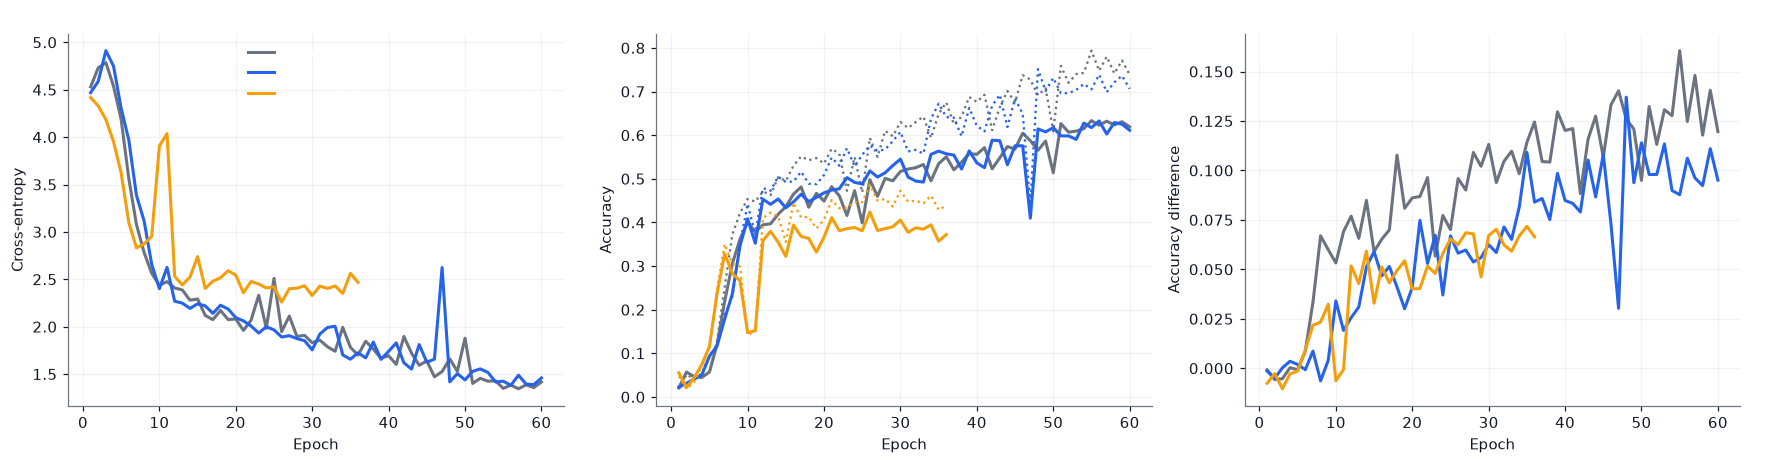

Augmentation with the highest validation top-1 accuracy: Horizontal flip


In [13]:
rows = []
for kind in aug_kinds:
    h, mon = scratch[kind]["hist"], scratch[kind]["monitor"]
    best = int(np.argmin(h["val_loss"]))
    rows.append({"augmentation": aug_titles[kind], "epochs run": len(h["loss"]), "best epoch": best + 1,
                 "train top-1 (no augmentation)": round(mon.train_acc[best], 3), "val top-1": round(h["val_accuracy"][best], 3),
                 "val top-5": round(h["val_top5_accuracy"][best], 3), "val loss": round(h["val_loss"][best], 3),
                 "generalization gap": round(mon.train_acc[best] - h["val_accuracy"][best], 3), "training time (s)": round(scratch[kind]["seconds"])})
e1_table = pd.DataFrame(rows).set_index("augmentation")
display(e1_table)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for kind in aug_kinds:
    h, mon, color = scratch[kind]["hist"], scratch[kind]["monitor"], aug_colors[kind]
    ep = np.arange(1, len(h["val_loss"]) + 1)
    axes[0].plot(ep, h["val_loss"], color=color, label=aug_titles[kind])
    axes[1].plot(ep, h["val_accuracy"], color=color, label=aug_titles[kind])
    axes[1].plot(ep, mon.train_acc, color=color, linestyle=":", linewidth=1.5)
    axes[2].plot(ep, np.array(mon.train_acc) - np.array(h["val_accuracy"]), color=color)
axes[0].set_title("Validation loss"); axes[0].set_ylabel("Cross-entropy")
axes[1].set_title("Top-1 accuracy (solid: validation, dotted: training without augmentation)"); axes[1].set_ylabel("Accuracy")
axes[2].set_title("Generalization gap (training \u2212 validation accuracy)"); axes[2].set_ylabel("Accuracy difference")
for ax in axes:
    ax.set_xlabel("Epoch")
axes[0].legend(fontsize=8.5)
finish(fig, "03_augmentation_experiment")

best_aug = max(aug_kinds, key=lambda k: e1_table.loc[aug_titles[k], "val top-1"])
print("Augmentation with the highest validation top-1 accuracy:", aug_titles[best_aug])

How to read this (compare with your own numbers):

- Without augmentation the training accuracy (dotted) approaches 100% while the validation accuracy lags far behind: a **large generalization gap**.
- Augmentation **narrows the gap** and usually **raises the validation accuracy**; the stronger pipeline typically helps more than horizontal flips alone, at the price of slower training (more epochs).
- These are single runs: differences between the two augmented settings may be within seed-to-seed variation (Notebook 06). The *gap* between "none" and "augmented" is the robust message.
- More augmentation is not always better: transformations that are too strong create unrealistic images or alter the label.

The augmentation with the best validation accuracy (declared rule) is used for the from-scratch model in the final comparison and for the fine-tuning in Section 11.

## 10. Experiment E2 — frozen pretrained features (feature extraction)

### 10.1 Loading MobileNetV2

**MobileNetV2** (Sandler *et al.*, 2018) is a compact CNN of about 2.2 million parameters (without its classifier) that reaches good accuracy on ImageNet with little computation, which makes it a convenient choice for a CPU. We load it **without its top classifier** (`include_top=False`) and with **global average pooling** (`pooling="avg"`), so that it returns one 1280-dimensional feature vector per image. The weights are downloaded the first time.

In [15]:
import os
import time

def load_backbone(size):
    # Load pretrained MobileNetV2 weights from the local Keras models directory.
    # Download the weights manually if they are not already available.
    filename = (
        f"mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_{size}_no_top.h5"
    )

    weights_path = os.path.join(
        os.path.expanduser("~"),
        ".keras",
        "models",
        filename
    )

    # Check whether the pretrained weights exist locally.
    if not os.path.isfile(weights_path):
        raise FileNotFoundError(
            f"Pretrained weights not found:\n{weights_path}\n\n"
            "Download the weights manually and place the file in "
            "the .keras/models directory."
        )

    try:
        # Load MobileNetV2 without its original classification head.
        # Using the local file avoids automatic downloads and network errors.
        return keras.applications.MobileNetV2(
            input_shape=(size, size, 3),
            include_top=False,
            weights=weights_path,
            pooling="avg"
        )

    except Exception as error:
        raise RuntimeError(
            f"Could not load the local MobileNetV2 weights: {error}"
        ) from error


# Load the pretrained backbone.
backbone = load_backbone(SIZE_PRETRAINED)

# Inspect the backbone architecture and parameter count.
n_backbone = backbone.count_params()
FEATURE_DIM = int(backbone.output.shape[-1])

print(
    f"MobileNetV2 backbone: {n_backbone:,} parameters | "
    f"output: {FEATURE_DIM} features per image | "
    f"layers: {len(backbone.layers)}"
)

# Estimate the number of parameters in the linear classification head.
head_params = FEATURE_DIM * N_CLASSES + N_CLASSES

print(
    f"Linear head on top: {head_params:,} parameters "
    f"({100 * head_params / n_backbone:.1f}% of the backbone)"
)


# Build a feature extractor using the pretrained backbone.
# MobileNetV2 expects input pixel values scaled to the [-1, 1] range.
feature_extractor = keras.Sequential(
    [
        keras.layers.Input(
            shape=(SIZE_PRETRAINED, SIZE_PRETRAINED, 3)
        ),
        keras.layers.Rescaling(
            1 / 127.5,
            offset=-1,
            name="to_minus1_1"
        ),
        backbone
    ],
    name="feature_extractor"
)


# Extract features separately for the training, validation, and test sets.
# These features can later be used to train a lightweight classifier.
features = {}
t0 = time.time()

for part in ("train", "val", "test"):
    features[part] = feature_extractor.predict(
        X128[part],
        batch_size=128,
        verbose=0
    )

print(
    f"Features extracted for all images in {time.time() - t0:.0f} s:",
    {k: v.shape for k, v in features.items()}
)

MobileNetV2 backbone: 2,257,984 parameters | output: 1280 features per image | layers: 155
Linear head on top: 130,662 parameters (5.8% of the backbone)
Features extracted for all images in 58 s: {'train': (4923, 1280), 'val': (1633, 1280), 'test': (1633, 1280)}


### 10.2 Why do the features work? A first look

We compare the training images as raw pixels (64 × 64 × 3 = 12,288 numbers) and as pretrained features (1,280 numbers), using the separation ratio $J = \operatorname{tr}S_B/\operatorname{tr}S_W$ of Section 7.3 on all 102 classes, and a PCA projection of 10 classes. PCA is unsupervised and fitted on training images only; it is shown for insight, not used in any model.

Separation ratio J on the training images, all 102 classes:
  raw pixels (12,288 numbers)         : 0.187
  pretrained features (1280 numbers): 0.316   (1.7x larger)


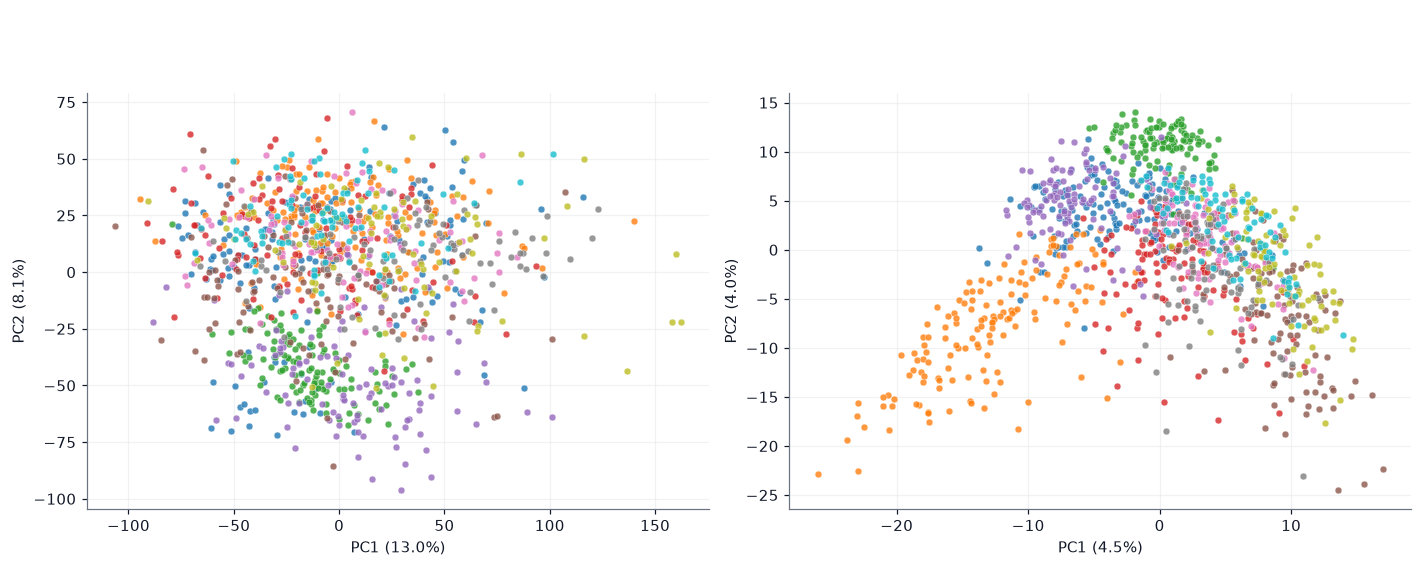

In [16]:
def separation_ratio(Fm, labels):
    """J = tr(S_B) / tr(S_W) of the features Fm for the class labels, after standardizing each feature."""
    Fm = (Fm - Fm.mean(axis=0)) / (Fm.std(axis=0) + 1e-8)
    mu = Fm.mean(axis=0)
    tr_b = tr_w = 0.0
    for c in np.unique(labels):
        Xc = Fm[labels == c]
        mc = Xc.mean(axis=0)
        tr_b += len(Xc) * np.sum((mc - mu) ** 2)
        tr_w += np.sum((Xc - mc) ** 2)
    return float(tr_b / tr_w)

pixels_train = X64["train"].reshape(len(y["train"]), -1).astype(np.float32)
J_pixels, J_features = separation_ratio(pixels_train, y["train"]), separation_ratio(features["train"], y["train"])
print(f"Separation ratio J on the training images, all {N_CLASSES} classes:")
print(f"  raw pixels ({pixels_train.shape[1]:,} numbers)         : {J_pixels:.3f}")
print(f"  pretrained features ({FEATURE_DIM} numbers): {J_features:.3f}   ({J_features / J_pixels:.1f}x larger)")

def pca_2d(Fm):
    Fm = (Fm - Fm.mean(axis=0)) / (Fm.std(axis=0) + 1e-8)
    U, S, Vt = np.linalg.svd(Fm, full_matrices=False)
    return Fm @ Vt[:2].T, S[:2] ** 2 / np.sum(S ** 2)

ten = np.argsort(-np.bincount(y["train"]))[:10]
mask = np.isin(y["train"], ten)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.0))
for ax, (Fm, title) in zip(axes, [(pixels_train[mask], "Raw pixels"), (features["train"][mask], "Pretrained MobileNetV2 features")]):
    proj, ratios = pca_2d(Fm)
    for k, c in enumerate(ten):
        sel = y["train"][mask] == c
        ax.scatter(proj[sel, 0], proj[sel, 1], s=20, alpha=0.8, color=plt.cm.tab10(k), edgecolor="white", linewidth=0.3)
    ax.set_xlabel(f"PC1 ({100 * ratios[0]:.1f}%)"); ax.set_ylabel(f"PC2 ({100 * ratios[1]:.1f}%)"); ax.set_title(title)
fig.suptitle("The ten largest classes projected onto two principal components (colour = class)", fontsize=12, fontweight="bold", x=0.01, ha="left", y=1.02)
finish(fig, "04_pca_pixels_vs_features")

### 10.3 Two linear probes on the frozen features

**(a) Ridge classifier (closed form).** As in Notebook 07, we regress the one-hot class indicators on the standardized features. In primal form, with $X \in \mathbb{R}^{N \times d}$ standardized, $\bar{Y}$ the mean of the one-hot targets, and penalty $\lambda$:

$$
W = (X^{\top}X + \lambda I)^{-1}X^{\top}(Y - \bar{Y}), \qquad \text{scores} = X_{\text{new}}W + \bar{Y}.
$$

Here $d = 1280 < N$, so the $1280 \times 1280$ system is cheap. We choose $\lambda$ on the validation set.

**(b) Softmax head in Keras.** `Dropout(0.2)` + `Dense(102, softmax)` on the raw features, trained with Adam on the precomputed features (seconds). We keep it on the *raw* features (no normalization layer) so that its weights can be **transplanted** into the full network for fine-tuning (Section 11).

In [17]:
def ridge_probe_fit(F_tr, y_tr, lam):
    mu, sd = F_tr.mean(axis=0), F_tr.std(axis=0) + 1e-8
    X = (F_tr - mu) / sd
    Y = np.eye(N_CLASSES)[y_tr]; y_bar = Y.mean(axis=0)
    W = np.linalg.solve(X.T @ X + lam * np.eye(X.shape[1]), X.T @ (Y - y_bar))
    return {"mu": mu, "sd": sd, "W": W, "y_bar": y_bar}

def ridge_probe_scores(probe, F):
    return ((F - probe["mu"]) / probe["sd"]) @ probe["W"] + probe["y_bar"]

lambdas = [1, 10, 100, 1000, 10000]
val_top1_by_lambda = {}
for lam in lambdas:
    probe = ridge_probe_fit(features["train"], y["train"], lam)
    val_top1_by_lambda[lam] = float(np.mean(ridge_probe_scores(probe, features["val"]).argmax(1) == y["val"]))
best_lambda = max(val_top1_by_lambda, key=val_top1_by_lambda.get)
ridge_probe = ridge_probe_fit(features["train"], y["train"], best_lambda)
print("Validation top-1 accuracy of the ridge probe by penalty:", {k: round(v, 3) for k, v in val_top1_by_lambda.items()})
print("Selected penalty:", best_lambda)

def build_head(dim=FEATURE_DIM, dropout=0.2):
    return keras.Sequential([keras.layers.Input(shape=(dim,)), keras.layers.Dropout(dropout, name="head_dropout"),
                             keras.layers.Dense(N_CLASSES, activation="softmax", name="head")], name="softmax_head")

keras.utils.set_random_seed(SEED)
head_model = build_head()
head_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy",
                   metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")])
head_history = head_model.fit(features["train"], y["train"], validation_data=(features["val"], y["val"]), epochs=epochs_for(150), batch_size=128,
                              callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)], verbose=0)
print(f"Softmax head: {len(head_history.history['loss'])} epochs | best validation top-1: {max(head_history.history['val_accuracy']):.3f}")

Validation top-1 accuracy of the ridge probe by penalty: {1: 0.857, 10: 0.855, 100: 0.855, 1000: 0.846, 10000: 0.777}
Selected penalty: 1
Softmax head: 56 epochs | best validation top-1: 0.896


## 11. Experiment E3 — fine-tuning

We now follow the three rules of Section 7.4:

1. **Start from the trained head**: the full network is built as `augmentation → Rescaling(1/127.5, offset=−1) → MobileNetV2 → Dropout → Dense`, and the `Dense` layer receives the weights learned in Section 10.3 (b).
2. **Unfreeze only the top layers** of the backbone (here the last 30 layers) and train with a **small learning rate** ($10^{-4}$).
3. **Keep all BatchNorm layers frozen.**

The augmentation is the one selected in E1. After fine-tuning we measure **how far every layer moved**: the relative change $\lVert W - W_0\rVert / \lVert W_0\rVert$ of its kernel with respect to the pretrained weights $W_0$.

In [18]:
N_UNFREEZE = 30

def build_finetune_model(aug_kind, head_weights, dropout=0.2):
    layers = [keras.layers.Input(shape=(SIZE_PRETRAINED, SIZE_PRETRAINED, 3), name="image")]
    augmentation = make_augmentation(aug_kind)
    if augmentation is not None:
        layers.append(augmentation)
    layers += [keras.layers.Rescaling(1 / 127.5, offset=-1, name="to_minus1_1"), backbone,
               keras.layers.Dropout(dropout, name="head_dropout"), keras.layers.Dense(N_CLASSES, activation="softmax", name="head")]
    model = keras.Sequential(layers, name="finetuned_mobilenetv2")
    model.get_layer("head").set_weights(head_weights)                              # rule 1: start from the trained head
    return model

keras.utils.set_random_seed(SEED)
finetune_model = build_finetune_model(best_aug, head_model.get_layer("head").get_weights())

# Rules 2 and 3: unfreeze the top layers only, and keep every BatchNorm layer frozen (inference mode).
backbone.trainable = True
for layer in backbone.layers[:-N_UNFREEZE]:
    layer.trainable = False
for layer in backbone.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

n_trainable = sum(int(np.prod(w.shape)) for w in finetune_model.trainable_weights)
n_total = finetune_model.count_params()
print(f"Trainable parameters: {n_trainable:,} of {n_total:,} ({100 * n_trainable / n_total:.1f}%)")

weights_before = {layer.name: [w.copy() for w in layer.get_weights()] for layer in backbone.layers if layer.get_weights()}

Trainable parameters: 1,641,382 of 2,388,646 (68.7%)


In [19]:
finetune_model.compile(optimizer=keras.optimizers.Adam(1e-4), loss="sparse_categorical_crossentropy",
                       metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy"), keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5_accuracy")])
ft_monitor = InferenceTrainEval(X128["train"][subset_idx[:400]], y["train"][subset_idx[:400]])
t0 = time.time()
ft_history = finetune_model.fit(X128["train"], y["train"], validation_data=(X128["val"], y["val"]), epochs=epochs_for(10), batch_size=32,
                                callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True), ft_monitor], verbose=2)
ft_seconds = time.time() - t0
fth = ft_history.history
best_ft = int(np.argmin(fth["val_loss"]))
print(f"\nFine-tuning: {len(fth['loss'])} epochs, {ft_seconds:.0f} s | best epoch {best_ft + 1} | validation top-1 {fth['val_accuracy'][best_ft]:.3f}, top-5 {fth['val_top5_accuracy'][best_ft]:.3f}")
print(f"Validation top-1 of the frozen-feature softmax head (before fine-tuning): {max(head_history.history['val_accuracy']):.3f}")

Epoch 1/10
154/154 - 56s - 366ms/step - accuracy: 0.9519 - loss: 0.1625 - top5_accuracy: 0.9970 - val_accuracy: 0.8647 - val_loss: 0.5192 - val_top5_accuracy: 0.9712
Epoch 2/10
154/154 - 48s - 309ms/step - accuracy: 0.9722 - loss: 0.0879 - top5_accuracy: 0.9992 - val_accuracy: 0.8739 - val_loss: 0.4931 - val_top5_accuracy: 0.9780
Epoch 3/10
154/154 - 48s - 314ms/step - accuracy: 0.9813 - loss: 0.0640 - top5_accuracy: 0.9994 - val_accuracy: 0.8745 - val_loss: 0.5188 - val_top5_accuracy: 0.9706
Epoch 4/10
154/154 - 48s - 310ms/step - accuracy: 0.9772 - loss: 0.0731 - top5_accuracy: 0.9998 - val_accuracy: 0.8702 - val_loss: 0.4851 - val_top5_accuracy: 0.9822
Epoch 5/10
154/154 - 47s - 308ms/step - accuracy: 0.9858 - loss: 0.0461 - top5_accuracy: 0.9996 - val_accuracy: 0.8885 - val_loss: 0.4774 - val_top5_accuracy: 0.9761
Epoch 6/10
154/154 - 48s - 313ms/step - accuracy: 0.9852 - loss: 0.0474 - top5_accuracy: 0.9998 - val_accuracy: 0.8904 - val_loss: 0.4972 - val_top5_accuracy: 0.9792
Epoc

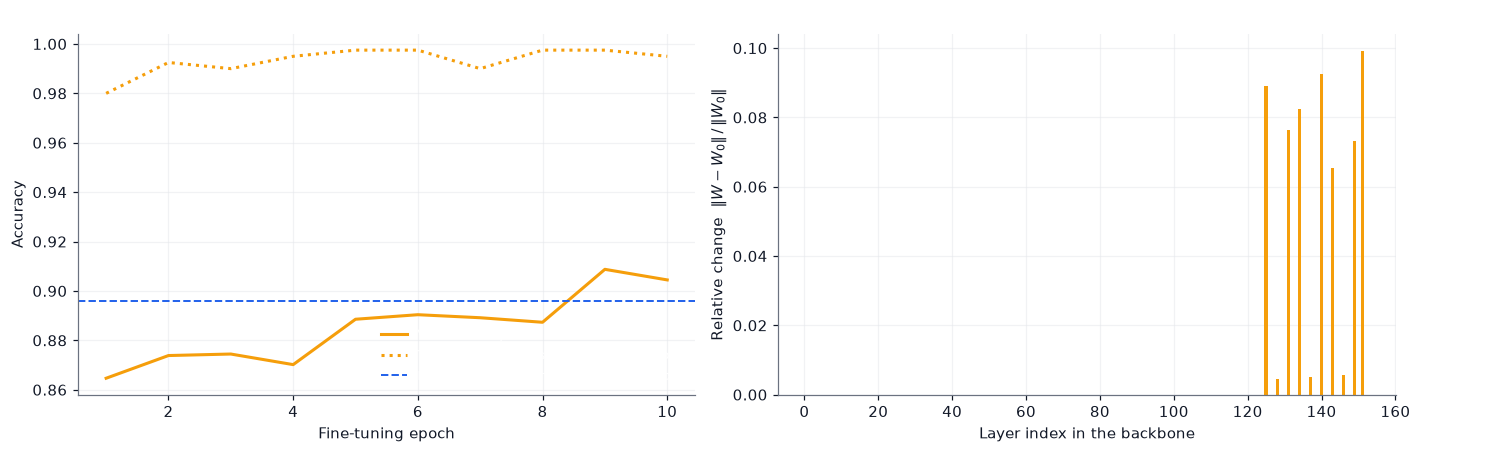

Unfrozen layers with weights: 10 | median relative change of the unfrozen kernels: 0.0747 | largest: 0.0992
Frozen layers moved by exactly: 0.0


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ep = np.arange(1, len(fth["val_loss"]) + 1)
axes[0].plot(ep, fth["val_accuracy"], color=COLORS["orange"], label="Validation top-1")
axes[0].plot(ep, ft_monitor.train_acc, color=COLORS["orange"], linestyle=":", label="Training top-1 (subset, no augmentation)")
axes[0].axhline(max(head_history.history["val_accuracy"]), color=COLORS["blue"], linestyle="--", linewidth=1.3, label="Frozen-feature softmax head (validation)")
axes[0].set_xlabel("Fine-tuning epoch"); axes[0].set_ylabel("Accuracy"); axes[0].set_title("Fine-tuning curve"); axes[0].legend(fontsize=8.5, loc="lower right")

# How far did each layer move from its pretrained weights?
names_l, rel_change, trainable_flag = [], [], []
for i, layer in enumerate(backbone.layers):
    if layer.name in weights_before:
        w0, w1 = weights_before[layer.name][0], layer.get_weights()[0]
        names_l.append(i); rel_change.append(float(np.linalg.norm(w1 - w0) / (np.linalg.norm(w0) + 1e-12))); trainable_flag.append(layer.trainable)
colors_l = [COLORS["orange"] if t else COLORS["light"] for t in trainable_flag]
axes[1].bar(names_l, rel_change, color=colors_l, width=0.9)
axes[1].set_xlabel("Layer index in the backbone"); axes[1].set_ylabel(r"Relative change  $\|W - W_0\| \,/\, \|W_0\|$")
axes[1].set_title("How far each layer moved (orange: unfrozen; grey: frozen, exactly 0)")
finish(fig, "05_finetuning")
changed = [(n, r) for n, r, t in zip(names_l, rel_change, trainable_flag) if t and r > 0]
print(f"Unfrozen layers with weights: {sum(trainable_flag)} | median relative change of the unfrozen kernels: {np.median([r for _, r in changed]):.4f}"
      f" | largest: {max(r for _, r in changed):.4f}")
print("Frozen layers moved by exactly:", max([r for r, t in zip(rel_change, trainable_flag) if not t], default=0.0))

Look at the right panel: only the unfrozen layers move, and even those change by a **small fraction** of their norm (typically a few percent): fine-tuning is a *small perturbation* of the pretrained solution, not a new training run — which is exactly why it needs little data and a small learning rate. Compare this with training from scratch, where the weights travel from a random initialization to a completely different point.

## 12. Comparing all approaches on the validation set, and selecting one

The four candidates:

| Method | Input size | Trained from |
|---|---|---|
| **CNN from scratch** (best augmentation of E1) | 64 × 64 | random initialization |
| **Ridge probe** on frozen MobileNetV2 features | 128 × 128 | pretrained backbone (frozen) |
| **Softmax probe** on frozen features | 128 × 128 | pretrained backbone (frozen) |
| **Fine-tuned MobileNetV2** | 128 × 128 | pretrained backbone (top layers adapted) |

Declared selection rule (as in Notebooks 07–08): **the highest validation top-1 accuracy.**

In [21]:
scratch_model = scratch[best_aug]["model"]

def scores_for(method, part):
    if method == "CNN from scratch":
        return scratch_model.predict(X64[part], batch_size=256, verbose=0)
    if method == "Ridge probe (frozen features)":
        return ridge_probe_scores(ridge_probe, features[part])
    if method == "Softmax probe (frozen features)":
        return head_model.predict(features[part], verbose=0)
    if method == "Fine-tuned MobileNetV2":
        return finetune_model.predict(X128[part], batch_size=128, verbose=0)
    raise ValueError(method)

methods = list(METHOD_COLORS)
val_scores = {m: scores_for(m, "val") for m in methods}
val_table = pd.DataFrame({m: {"val top-1": float(np.mean(val_scores[m].argmax(1) == y["val"])), "val top-5": float(np.mean(topk_correct(val_scores[m], y["val"], 5)))}
                          for m in methods}).T.round(3)
display(val_table)
selected_method = val_table["val top-1"].idxmax()
print("Selected method (highest validation top-1):", selected_method)

,val top-1,val top-5
CNN from scratch,0.633,0.867
Ridge probe (frozen features),0.857,0.958
Softmax probe (frozen features),0.893,0.982
Fine-tuned MobileNetV2,0.909,0.985


Selected method (highest validation top-1): Fine-tuned MobileNetV2


### 12.1 Test-time augmentation (TTA)

Augmentation can also be used **at prediction time**: average the predicted probabilities over several transformed copies of the test image. Averaging reduces the variance of the prediction. For a horizontal flip,

$$
\hat{p}_{\text{TTA}}(x) = \tfrac{1}{2}\big(\hat{p}(x) + \hat{p}(F_h x)\big).
$$

The cost is one extra forward pass per copy. Whether to use TTA is a design decision, so it is decided on the **validation** set with a rule declared in advance: *use it only if it improves the validation top-1 accuracy by at least 0.2 percentage points.* (It applies to the Keras image models; for the probes it would require re-extracting features.)

In [22]:
def predict_with_tta(method, part):
    plain = scores_for(method, part)
    X = X128[part] if method == "Fine-tuned MobileNetV2" else X64[part]
    model = finetune_model if method == "Fine-tuned MobileNetV2" else scratch_model
    flipped = model.predict(np.ascontiguousarray(X[:, :, ::-1]), batch_size=128, verbose=0)
    return 0.5 * (plain + flipped), plain

use_tta = False
if selected_method in ("Fine-tuned MobileNetV2", "CNN from scratch"):
    tta_val, plain_val = predict_with_tta(selected_method, "val")
    acc_plain, acc_tta = float(np.mean(plain_val.argmax(1) == y["val"])), float(np.mean(tta_val.argmax(1) == y["val"]))
    use_tta = (acc_tta - acc_plain) >= 0.002
    print(f"Validation top-1 of the selected method: plain {acc_plain:.4f} | with flip-TTA {acc_tta:.4f} | difference {acc_tta - acc_plain:+.4f}")
    print("TTA adopted for the test evaluation:", use_tta)
else:
    print("The selected method is a linear probe on frozen features: TTA is not applied here.")

Validation top-1 of the selected method: plain 0.9088 | with flip-TTA 0.9186 | difference +0.0098
TTA adopted for the test evaluation: True


## 13. Final evaluation on the test set

The test set is used **once**. We report top-1 and top-5 accuracy with 95% Wilson intervals for **all four methods** (the selection was made on the validation set, and no decision depends on the test numbers). Because all methods are evaluated on the **same test images**, we can compare them with **paired** procedures (Notebook 07):

- **McNemar's exact test** on the top-1 correctness of two methods (only images on which they disagree matter);
- a **paired bootstrap** interval for the difference in top-1 accuracy (resampling test images, the same images for both methods).

,top-1,top-5
method,,
CNN from scratch,"0.617 [0.593, 0.641]","0.860 [0.842, 0.876]"
Ridge probe (frozen features),"0.849 [0.831, 0.866]","0.961 [0.950, 0.969]"
Softmax probe (frozen features),"0.890 [0.874, 0.905]","0.982 [0.974, 0.987]"
Fine-tuned MobileNetV2 *,"0.909 [0.894, 0.922]","0.980 [0.972, 0.986]"


* selected on the validation set (with flip test-time augmentation). Test images: 1633. Chance: top-1 0.010, top-5 0.049.


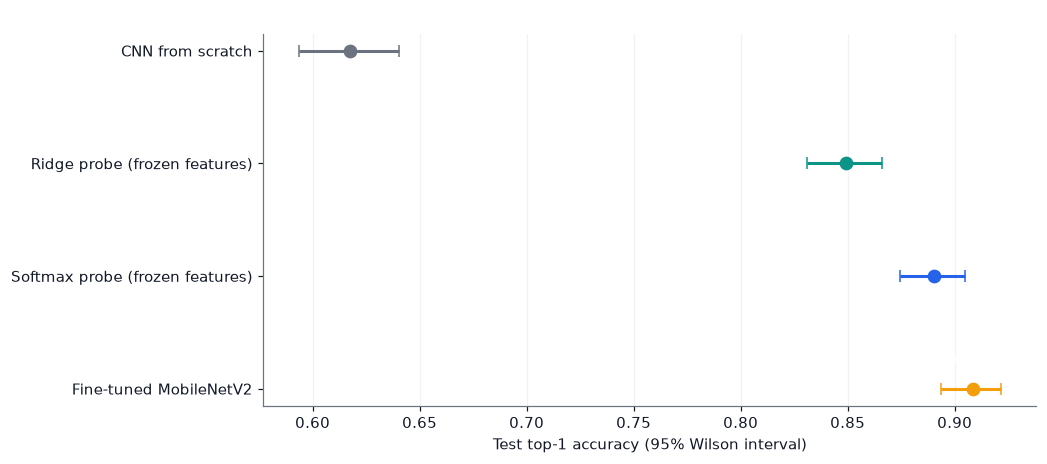

In [23]:
test_scores = {m: scores_for(m, "test") for m in methods}
if use_tta:
    test_scores[selected_method], _ = predict_with_tta(selected_method, "test")

n_test = len(y["test"])
rows, correct_top1 = [], {}
for m in methods:
    c1, c5 = test_scores[m].argmax(1) == y["test"], topk_correct(test_scores[m], y["test"], 5)
    correct_top1[m] = c1
    lo1, hi1 = wilson_interval(int(c1.sum()), n_test); lo5, hi5 = wilson_interval(int(c5.sum()), n_test)
    rows.append({"method": m + (" *" if m == selected_method else ""), "top-1": f"{c1.mean():.3f} [{lo1:.3f}, {hi1:.3f}]", "top-5": f"{c5.mean():.3f} [{lo5:.3f}, {hi5:.3f}]"})
display(pd.DataFrame(rows).set_index("method"))
print(f"* selected on the validation set{' (with flip test-time augmentation)' if use_tta else ''}. Test images: {n_test}. Chance: top-1 {1 / N_CLASSES:.3f}, top-5 {5 / N_CLASSES:.3f}.")

fig, ax = plt.subplots(figsize=(9.6, 4.3))
for k, m in enumerate(methods):
    c1 = correct_top1[m]; lo, hi = wilson_interval(int(c1.sum()), n_test)
    ax.errorbar([c1.mean()], [k], xerr=[[c1.mean() - lo], [hi - c1.mean()]], fmt="o", color=METHOD_COLORS[m], capsize=4, markersize=8)
    ax.text(c1.mean(), k - 0.22, f"{c1.mean():.3f}", ha="center", fontsize=9)
ax.set_yticks(range(len(methods))); ax.set_yticklabels(methods); ax.invert_yaxis()
ax.set_xlabel("Test top-1 accuracy (95% Wilson interval)"); ax.set_title("Test accuracy of the four approaches"); ax.grid(axis="y", visible=False)
finish(fig, "06_test_accuracy")

In [24]:
def paired_bootstrap_difference(correct_a, correct_b, n_boot=2000, seed=0):
    r = np.random.default_rng(seed); n = len(correct_a)
    diffs = np.empty(n_boot)
    for b in range(n_boot):
        idx = r.integers(0, n, size=n)
        diffs[b] = correct_a[idx].mean() - correct_b[idx].mean()
    return np.percentile(diffs, [2.5, 97.5])

rows = []
for other in methods:
    if other == selected_method:
        continue
    b, c, p = mcnemar_exact(correct_top1[selected_method], correct_top1[other])
    lo, hi = paired_bootstrap_difference(correct_top1[selected_method], correct_top1[other])
    rows.append({"selected vs": other, "accuracy difference": round(float(correct_top1[selected_method].mean() - correct_top1[other].mean()), 3),
                 "95% paired bootstrap": f"[{lo:+.3f}, {hi:+.3f}]", "only selected right": b, "only other right": c, "McNemar exact p": f"{p:.2g}"})
display(pd.DataFrame(rows).set_index("selected vs"))

,accuracy difference,95% paired bootstrap,only selected right,only other right,McNemar exact p
selected vs,,,,,
CNN from scratch,0.291,"[+0.268, +0.315]",515,39,4.5e-107
Ridge probe (frozen features),0.059,"[+0.043, +0.075]",142,45,6.6e-13
Softmax probe (frozen features),0.018,"[+0.005, +0.031]",78,48,0.0095


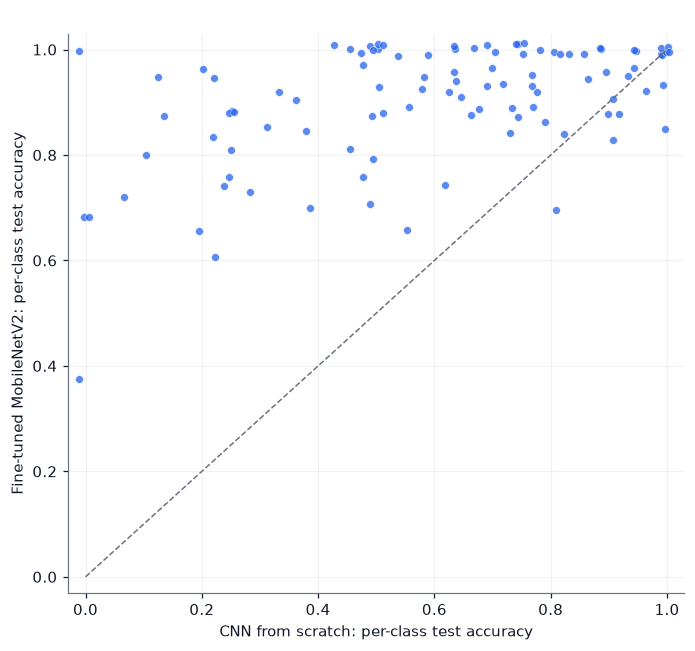

Classes better with the selected method: 87 | equal: 9 | worse: 6
(About 16 test images per class: a single image changes a class accuracy by about 6 points; small differences are noise.)


In [25]:
# Per-class view: does the improvement benefit most classes, or only a few?
reference = "CNN from scratch"
if selected_method != reference:
    k_sel = np.bincount(y["test"][correct_top1[selected_method]], minlength=N_CLASSES)
    k_ref = np.bincount(y["test"][correct_top1[reference]], minlength=N_CLASSES)
    n_cls = np.bincount(y["test"], minlength=N_CLASSES)
    acc_sel, acc_ref = k_sel / n_cls, k_ref / n_cls
    fig, ax = plt.subplots(figsize=(6.4, 6.0))
    ax.scatter(acc_ref + np.random.default_rng(0).uniform(-0.012, 0.012, N_CLASSES), acc_sel + np.random.default_rng(1).uniform(-0.012, 0.012, N_CLASSES),
               s=26, color=COLORS["blue"], alpha=0.75, edgecolor="white", linewidth=0.4)
    ax.plot([0, 1], [0, 1], color=COLORS["gray"], linestyle="--", linewidth=1)
    ax.set_xlabel(f"{reference}: per-class test accuracy"); ax.set_ylabel(f"{selected_method}: per-class test accuracy")
    ax.set_title("Each dot is one of the 102 classes"); ax.set_xlim(-0.03, 1.03); ax.set_ylim(-0.03, 1.03)
    finish(fig, "07_per_class_scatter")
    print(f"Classes better with the selected method: {int((acc_sel > acc_ref).sum())} | equal: {int((acc_sel == acc_ref).sum())} | worse: {int((acc_sel < acc_ref).sum())}")
    print("(About 16 test images per class: a single image changes a class accuracy by about 6 points; small differences are noise.)")

Compare the intervals and the paired tests: when the selected method is clearly better than the from-scratch CNN, the paired bootstrap interval of the difference excludes zero and McNemar's $p$-value is tiny; the per-class scatter shows that **most classes improve**, not just a few.

Remember the caveats of the comparison (Section 1.1): the from-scratch network sees 64 × 64 images and the pretrained one 128 × 128, so part of the gain may come from the resolution rather than from pretraining. Exercise B.6 proposes the control.

## 14. Data efficiency: accuracy against the number of training images

The main promise of transfer learning is that it needs **far fewer labelled images**. We measure the validation top-1 accuracy as a function of the number $m$ of training images per class:

- the **ridge probe** on frozen features (cheap, so 3 random subsets for each $m$);
- the **CNN from scratch** with the best augmentation (one run per size; it must be trained again for each subset, so we use only a few sizes).

For $m = $ "all" we reuse the results above (the training set has about 48 images per class on average).

Done in 868 s


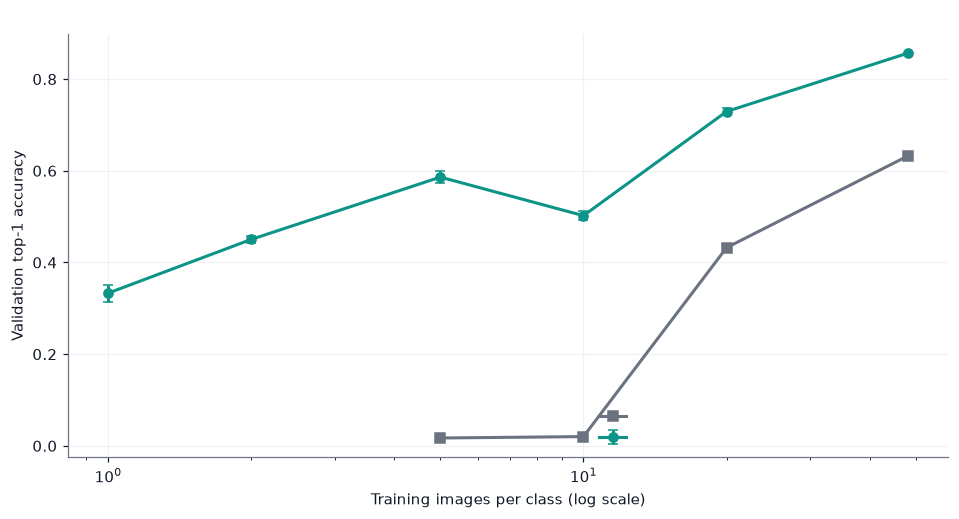

{1: 0.333, 2: 0.45, 5: 0.586, 10: 0.502, 20: 0.729} (ridge probe) | {5.0: 0.017, 10.0: 0.02, 20.0: 0.432, 48.3: 0.633} (from scratch)


In [26]:
def subsample_per_class(labels, m, seed):
    r = np.random.default_rng(seed); chosen = []
    for c in range(N_CLASSES):
        idx = r.permutation(np.flatnonzero(labels == c))
        chosen.append(idx[:m])
    return np.concatenate(chosen)

sizes_probe = [1, 2, 5, 10, 20]
sizes_scratch = [10] if QUICK_MODE else [5, 10, 20]
mean_all = len(y["train"]) / N_CLASSES

probe_curve = {}
for m in sizes_probe:
    accs = []
    for seed in range(3):
        idx = subsample_per_class(y["train"], m, seed)
        probe = ridge_probe_fit(features["train"][idx], y["train"][idx], best_lambda)
        accs.append(float(np.mean(ridge_probe_scores(probe, features["val"]).argmax(1) == y["val"])))
    probe_curve[m] = (np.mean(accs), np.std(accs))
probe_curve[mean_all] = (val_table.loc["Ridge probe (frozen features)", "val top-1"], 0.0)

scratch_curve = {}
t0 = time.time()
for m in sizes_scratch:
    idx = subsample_per_class(y["train"], m, 0)
    model_m, hist_m, _, _ = train_scratch(best_aug, X64["train"][idx], y["train"][idx], epochs_for(60), patience=10)
    scratch_curve[m] = float(hist_m["val_accuracy"][int(np.argmin(hist_m["val_loss"]))])
scratch_curve[mean_all] = val_table.loc["CNN from scratch", "val top-1"]
print(f"Done in {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(8.8, 4.8))
xs = sorted(probe_curve)
ax.errorbar(xs, [probe_curve[x][0] for x in xs], yerr=[probe_curve[x][1] for x in xs], marker="o", color=METHOD_COLORS["Ridge probe (frozen features)"], capsize=3, label="Ridge probe on frozen pretrained features")
xs2 = sorted(scratch_curve)
ax.plot(xs2, [scratch_curve[x] for x in xs2], marker="s", color=METHOD_COLORS["CNN from scratch"], label="CNN from scratch (augmented)")
ax.set_xscale("log"); ax.set_xlabel("Training images per class (log scale)"); ax.set_ylabel("Validation top-1 accuracy")
ax.set_title("Pretrained features need far fewer labelled images"); ax.legend(loc="lower right")
finish(fig, "08_data_efficiency")
print({m: round(float(probe_curve[m][0]), 3) for m in sizes_probe}, "(ridge probe) |", {round(float(m), 1): round(float(v), 3) for m, v in scratch_curve.items()}, "(from scratch)")

The curves usually show the typical pattern: with a handful of images per class, the probe on pretrained features is already far above chance and above the network trained from scratch; the gap narrows as more images become available, but for this dataset it rarely closes entirely.

## 15. Interpretation and caveats

**What the results can support.** Pretrained features plus a small amount of adaptation give a clear improvement over a small CNN trained from scratch, particularly with few images per class, and augmentation reduces overfitting when training from scratch.

**What they do not support, and what to watch.**

1. **Domain overlap and contamination.** ImageNet contains photographs of flowers (and of many plants and scenes). The pretrained features may therefore be *especially* suitable for flowers, and it is possible that images similar or identical to our *test images* appeared in the pretraining data. We cannot rule this out, so the test accuracy may overestimate performance on genuinely new data, and the benefit of transfer learning for **unrelated** domains (microscopy, histology, spectrograms) is usually smaller — it must be measured, not assumed. For biomedical images, in-domain pretraining or self-supervised pretraining on the target modality can help more than ImageNet.
2. **The comparison is confounded** by input resolution (64 vs 128 pixels), by the number of parameters, and by the training budget.
3. **Near-duplicate photographs** of the same plant may lie in different partitions (Notebook 08); this affects all methods, and may favour methods with strong memorization abilities.
4. **One run per configuration** (except the probe curves): small differences between the models are not significant (Notebooks 06 and 07).
5. **Augmentation must be label-preserving.** Rotations and flips are valid for flowers; they would be wrong for, e.g., chirality-dependent structures or orientation-specific medical images.
6. **Licensing and provenance.** Pretrained weights come with their own licences and were trained on data whose provenance and biases you inherit; check the terms before using them in a product.
7. **Compute and carbon.** Fine-tuning is far cheaper than pretraining, which is one reason to reuse pretrained models responsibly.

## 16. Saving the selected model with its metadata

In [27]:
meta = {
    "dataset": "Oxford 102 Flowers (Nilsback and Zisserman, 2008)",
    "split": {"kind": "stratified, same function and seed as Notebook 08", "seed": SEED, "train": int(len(y["train"])), "validation": int(len(y["val"])), "test": int(len(y["test"]))},
    "selected_method": selected_method, "selection_rule": "highest validation top-1 accuracy", "test_time_augmentation": bool(use_tta),
    "best_augmentation_from_E1": best_aug,
    "validation_top1": {m: float(val_table.loc[m, "val top-1"]) for m in methods},
    "test_top1": {m: float(correct_top1[m].mean()) for m in methods},
    "backbone": {"name": "MobileNetV2", "weights": "imagenet", "input_size": SIZE_PRETRAINED, "preprocessing": "Rescaling(1/127.5, offset=-1) inside the model",
                 "unfrozen_last_layers": N_UNFREEZE, "batchnorm_frozen": True, "fine_tuning_learning_rate": 1e-4},
    "versions": {"python": sys.version.split()[0], "keras": keras.__version__, "backend": keras.backend.backend(), "numpy": np.__version__},
}
with open(os.path.join(ARTIFACT_DIR, "flowers102_transfer_metadata.json"), "w") as f:
    json.dump(meta, f, indent=2)

if selected_method == "Fine-tuned MobileNetV2":
    path = os.path.join(ARTIFACT_DIR, "flowers102_finetuned_mobilenetv2.keras"); finetune_model.save(path)
elif selected_method == "CNN from scratch":
    path = os.path.join(ARTIFACT_DIR, "flowers102_cnn_augmented.keras"); scratch_model.save(path)
elif selected_method == "Softmax probe (frozen features)":
    path = os.path.join(ARTIFACT_DIR, "flowers102_softmax_probe.keras"); head_model.save(path)
else:
    path = os.path.join(ARTIFACT_DIR, "flowers102_ridge_probe.npz"); np.savez(path, **ridge_probe)
print("Saved:", path)

if selected_method == "Fine-tuned MobileNetV2":
    reloaded = keras.models.load_model(path)
    print("Reloaded predictions identical:", np.allclose(reloaded.predict(X128["test"][:8], verbose=0), finetune_model.predict(X128["test"][:8], verbose=0), atol=1e-4))

Saved: artifacts_09\flowers102_finetuned_mobilenetv2.keras
Reloaded predictions identical: True


## 17. What did we learn?

1. **Rescaling** needs interpolation; bilinear interpolation averages the 4 nearest pixels, and shrinking an image without antialiasing creates **aliasing** (moiré). Use a library that antialiases and apply exactly the same resizing in training and prediction.
2. **Augmentation** minimizes a *vicinal risk*: random label-preserving transformations replace each image by its neighbourhood. Geometric transformations are **affine maps** (matrices in homogeneous coordinates, applied by inverse mapping with bilinear sampling; their order matters). For a linear model, input noise equals an **L2 penalty** $\sigma^2\lVert w\rVert^2$.
3. Augmentation layers in Keras are random in training and the identity at inference; the **training accuracy must be measured without augmentation** to see the generalization gap. Augmentation narrowed the gap of the CNN from scratch.
4. **Transfer learning** reuses a feature extractor trained on a large source task. A **linear probe** on frozen features trains in seconds (closed-form ridge or a softmax head) and the features separate the classes much better than raw pixels ($J$ ratio, PCA).
5. **Fine-tuning** rules: start from a trained head, unfreeze only the top layers with a small learning rate, keep BatchNorm frozen. The weights move only slightly from the pretrained solution.
6. Preprocessing must **match the pretraining** (here $[-1, 1]$ scaling).
7. Methods evaluated on the same test images are compared with **paired** procedures (McNemar, paired bootstrap).
8. **Data-efficiency curves** show where transfer learning pays off most: with few images per class.
9. Caveats: **domain overlap and contamination**, confounded comparisons (resolution), near-duplicates, and licensing.

### Key terms

| Term | Meaning |
|---|---|
| Interpolation, aliasing | Computing pixel values on a new grid / false low-frequency patterns from insufficient low-pass filtering |
| Vicinal risk | Average loss over random transformations of each training sample |
| Affine map | Rotation, scaling, translation, flip (and shear) as a $3\times3$ matrix |
| Inverse mapping | Computing each output pixel by looking up where it comes from in the input |
| Test-time augmentation | Averaging predictions over transformed copies of the input |
| Backbone, head | Convolutional feature extractor / final classifier layer(s) |
| Feature extraction, linear probe | Training only the head on frozen features |
| Fine-tuning | Training the head and the top part of the backbone with a small learning rate |
| Frozen layer | A layer with `trainable = False` (BatchNorm then runs in inference mode) |
| Separation ratio $J$ | $\operatorname{tr}S_B / \operatorname{tr}S_W$, a measure of class separability in a feature space |
| Contamination | Overlap between pretraining data and test data |

## 18. Exercises

### A. Mathematics

1. A bilinear interpolation at position $(x, y) = (10.3, 4.8)$ uses the four pixels $(10,4), (11,4), (10,5), (11,5)$. Write the four weights and show that they are non-negative and sum to 1.
2. Show that horizontal flip $F_h$ is an involution ($F_h^2 = I$) and compute the matrix of a rotation by $\theta$ about a centre $c = (c_x, c_y)$ explicitly, as $T(c)R(\theta)T(-c)$.
3. Prove that the composition of two affine maps is affine, and that scaling by $s$ followed by translation by $t$ differs from translation by $t$ followed by scaling by $s$.
4. Show that training a *logistic* regression on noise-augmented inputs does **not** give exactly a ridge penalty, but approximately does for small $\sigma$ (second-order Taylor expansion of the loss in $\varepsilon$).
5. Let $f$ be invariant to flips, i.e. $f(F_hx) = f(x)$. Show that flip augmentation then has no effect on the loss, and explain why training a non-invariant network with flip augmentation *forces* invariance on the training images.
6. Compute the number of parameters of a linear head on 1280 features for 102 classes, and compare with a fine-tuned top block of $3$ convolutions of $3\times3\times160\times160$ kernels.
7. Derive the separation ratio $J$ for two classes in one dimension with equal sizes, means $\pm a$, and common variance $\sigma^2$. How does $J$ relate to the classification accuracy of the best threshold?
8. With a pretrained solution $\theta_0$, and the penalty $\tfrac{\lambda}{2}\lVert\theta-\theta_0\rVert^2$, derive the gradient step $\theta \leftarrow \theta - \eta(\nabla L + \lambda(\theta-\theta_0))$ and show that it is a weight decay towards $\theta_0$ instead of towards 0.

### B. Programming

1. Replace `MobileNetV2` with another backbone from `keras.applications` (for example `EfficientNetB0`, `ResNet50`); remember to use the matching preprocessing. Compare accuracy, parameters, and time.
2. Try `SIZE_PRETRAINED = 96`, `160`, and `224`. How do accuracy and run time change?
3. Vary `N_UNFREEZE` in $\{0, 10, 30, 60, \text{all layers except BatchNorm}\}$ and plot the validation accuracy.
4. Fine-tune with the BatchNorm layers **unfrozen** and compare. What happens to the validation accuracy in the first epochs?
5. Implement mixup ($x = \lambda x_i + (1-\lambda)x_j$, $y$ mixed in the same way) and **CutMix** for the CNN from scratch and compare with E1.
6. **Control for the resolution:** train the CNN from scratch at 128 × 128 (and adapt the pooling depth) and compare it with the fine-tuned model at 128 × 128.
7. Implement the **L2-SP penalty** as a custom regularizer or loss term and compare it with plain fine-tuning.
8. Use multiple TTA transformations (flip, several small shifts and zooms) and measure the improvement of the validation accuracy as a function of the number of copies.
9. Compute the occlusion-sensitivity maps of Notebook 08 for the fine-tuned model and compare them with the from-scratch CNN on the same images. Does the fine-tuned model focus more on the flower?

### C. Research thinking

1. You want to classify histology patches from 40 patients with a few hundred patches each. Would you use an ImageNet-pretrained backbone, and how would you test whether it is better than training from scratch? How should the split be done (hint: Notebook 07, grouped by patient)?
2. How could you test whether the ImageNet pretraining data contain near-duplicates of your test images? What would you do if they do?
3. Which of the augmentations of this notebook would **not** be label-preserving for (a) images of a chiral molecule, (b) chest X-rays, (c) images of a stained tissue in which colour intensity encodes a biomarker? Propose an appropriate augmentation for each.
4. A colleague reports that fine-tuning "improved accuracy from 71% to 78%" on a test set of 200 images. What additional information would you need before believing that the improvement is real?

## 19. Further exploration and references

### Dataset and models

- Nilsback, M.-E. and Zisserman, A. (2008). Automated flower classification over a large number of classes. *Indian Conference on Computer Vision, Graphics and Image Processing*.
- Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., and Chen, L.-C. (2018). MobileNetV2: inverted residuals and linear bottlenecks. *CVPR*.
- Russakovsky, O., *et al.* (2015). ImageNet large scale visual recognition challenge. *International Journal of Computer Vision*, 115, 211–252.

### Transfer learning

- Yosinski, J., Clune, J., Bengio, Y., and Lipson, H. (2014). How transferable are features in deep neural networks? *NeurIPS*.
- Kornblith, S., Shlens, J., and Le, Q. V. (2019). Do better ImageNet models transfer better? *CVPR*.
- Raghu, M., Zhang, C., Kleinberg, J., and Bengio, S. (2019). Transfusion: understanding transfer learning for medical imaging. *NeurIPS*.
- Li, X., Grandvalet, Y., and Davoine, F. (2018). Explicit inductive bias for transfer learning with convolutional networks. *ICML* (L2-SP).

### Augmentation

- Chapelle, O., Weston, J., Bottou, L., and Vapnik, V. (2000). Vicinal risk minimization. *NeurIPS*.
- Bishop, C. M. (1995). Training with noise is equivalent to Tikhonov regularization. *Neural Computation*, 7(1), 108–116.
- Shorten, C. and Khoshgoftaar, T. M. (2019). A survey on image data augmentation for deep learning. *Journal of Big Data*, 6, 60.
- Zhang, H., Cissé, M., Dauphin, Y., and Lopez-Paz, D. (2018). mixup: beyond empirical risk minimization. *ICLR*.
- Cubuk, E. D., *et al.* (2019). AutoAugment: learning augmentation strategies from data. *CVPR*.

### Keras documentation

- [Transfer learning and fine-tuning guide](https://keras.io/guides/transfer_learning/)
- [`keras.applications`](https://keras.io/api/applications/) (MobileNetV2, EfficientNet, ResNet)
- [Image augmentation layers](https://keras.io/api/layers/preprocessing_layers/image_augmentation/)

### Suggested reading

- Goodfellow, Bengio, and Courville — *Deep Learning*: section 7.4 (dataset augmentation), section 7.7 (multitask learning and transfer).
- Chollet — *Deep Learning with Python*: the sections on data augmentation and on using a pretrained model.
- Géron — *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*: the chapter on pretrained models for transfer learning.

---

## Next notebook

**10 — Deep Learning for DNA Sequence Classification**

We move from images to **biological sequences**: splice-junction detection in DNA (UCI Splice-junction Gene Sequences). We encode nucleotides (one-hot), introduce the **1D convolution** (the sequence analogue of the convolutions of Notebook 08), design a 1D CNN, and examine learned **motifs** — connecting the mathematics of this and the previous notebook to a classical problem of molecular biology.